# Load and map STAC results

In [18]:
import sys
from pathlib import Path
import json
import pandas as pd, geopandas as gpd
from shapely.geometry import shape
sys.path.insert(0, '/home/pmontesa/code/csda_summaries/lib')   # adjust
import searchlib, staclib
from datetime import date

In [7]:
root = Path.home() / "csda_stac_cache" / "global_search"
rows = []
for d in sorted(root.iterdir()):
    if not d.is_dir():
        continue
    m = json.loads((d / "manifest.json").read_text()) if (d / "manifest.json").exists() else {}
    n = len(list((d / "items").glob("*/*/*.geojson"))) if (d / "items").exists() else 0
    rows.append({"signature": d.name, "n_checkpoints": n,
                 "start": m.get("start_date"), "end": m.get("end_date"),
                 "tile_deg": m.get("tile_size_degrees"),
                 "collections": ",".join(m.get("collections") or [])})
display(pd.DataFrame(rows).sort_values("n_checkpoints", ascending=False))

,signature,n_checkpoints,start,end,tile_deg,collections
2,e3655091bc88bc19,4518,1999-01-01,2026-09-30,20,planet
0,11e505c59ade8a24,3812,1999-01-01,2026-09-29,20,planet
1,769866e01d7d5a56,3239,1999-01-01,2018-01-01,20,planet


In [4]:
def load_light(run_dir, max_file_mb=None, periods=None):
    recs = []
    for f in sorted(Path(run_dir).glob('items/*/*/*.geojson')):
        if periods and f.parents[0].name not in periods:
            continue
        if max_file_mb and f.stat().st_size > max_file_mb * 1e6:
            print(f'  skipped {f.parents[0].name}/{f.stem} ({f.stat().st_size/1e6:.0f} MB)')
            continue
        for ft in json.loads(f.read_text())['features']:
            if not ft.get('geometry'):
                continue
            p = ft.get('properties') or {}
            recs.append({'id': ft.get('id'), 'collection': ft.get('collection'),
                         **{k: p.get(k) for k in KEEP},
                         'geometry': shape(ft['geometry'])})
    gdf = gpd.GeoDataFrame(recs, crs=4326).drop_duplicates('id')
    print(f'{len(gdf):,} unique items')
    return gdf

9,221,878 unique items


/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3

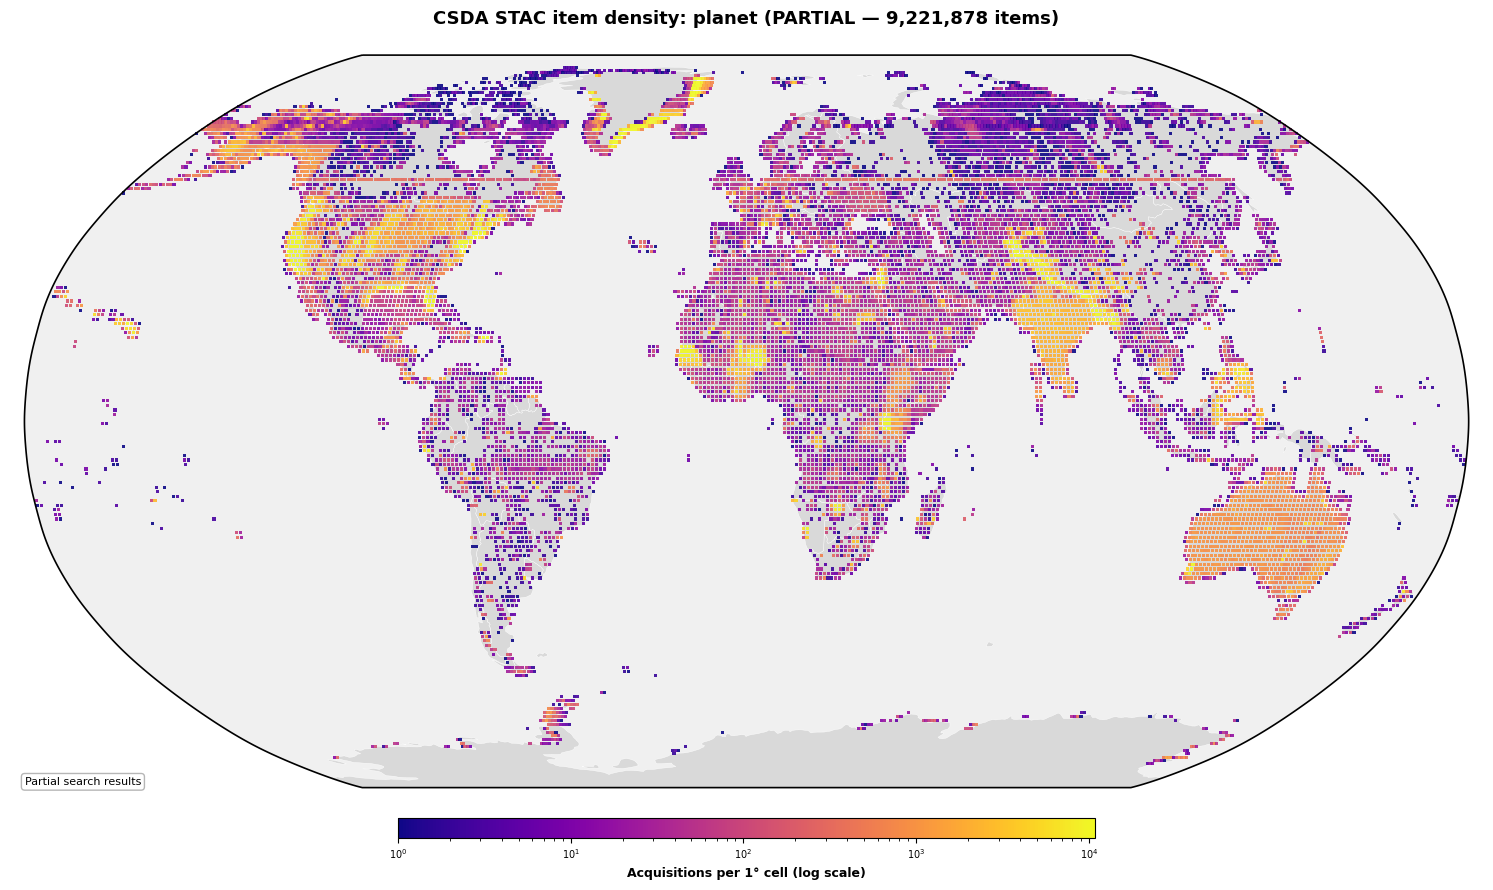

(<Figure size 1800x900 with 2 Axes>,
 <Axes: title={'center': 'CSDA STAC item density: planet (PARTIAL — 9,221,878 items)'}>)

In [5]:
RUN_DIR = Path('/explore/nobackup/people/pmontesa/csda_stac_cache/global_search/11e505c59ade8a24')
KEEP = ['datetime', 'platform', 'instrument']

stac_gdf = load_light(RUN_DIR)

if stac_gdf.empty:
    print('Nothing to map yet — check back once post-2014 slices complete.')
else:
    fig = staclib.plot_stac_acquisition_density(
        stac_gdf=stac_gdf, sites_gdf=None, bin_method='grid',
        title=f'CSDA STAC acquisition density: planet (PARTIAL — {len(stac_gdf):,} items)',
        filter_text='Partial search results',
        figsize=(18, 9))
    display(fig)

In [13]:
stac_gdf.collection.unique()

array(['planet'], dtype=object)

14,515,349 unique items


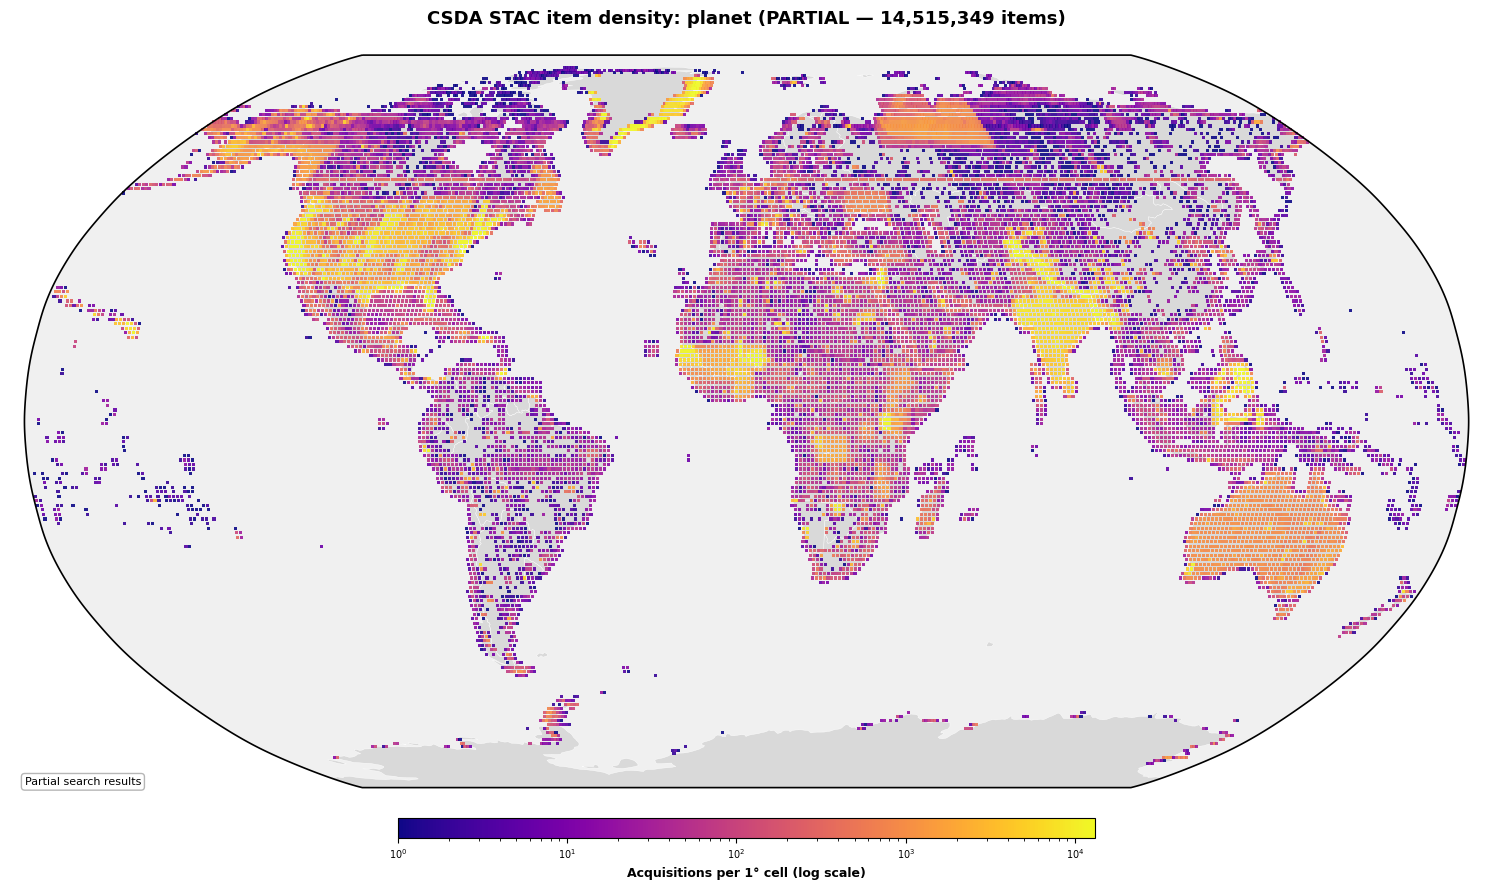

(<Figure size 1800x900 with 2 Axes>,
 <Axes: title={'center': 'CSDA STAC item density: planet (PARTIAL — 14,515,349 items)'}>)

In [14]:
RUN_DIR = Path('/explore/nobackup/people/pmontesa/csda_stac_cache/global_search/e3655091bc88bc19')
KEEP = ['datetime', 'platform', 'instrument']

stac_gdf = load_light(RUN_DIR)

if stac_gdf.empty:
    print('Nothing to map yet — check back once post-2014 slices complete.')
else:
    fig = staclib.plot_stac_acquisition_density(
        stac_gdf=stac_gdf, sites_gdf=None, bin_method='grid',
        title=f'CSDA STAC item density: planet (PARTIAL — {len(stac_gdf):,} items)',
        filter_text='Partial search results',
        figsize=(18, 9))
    display(fig)

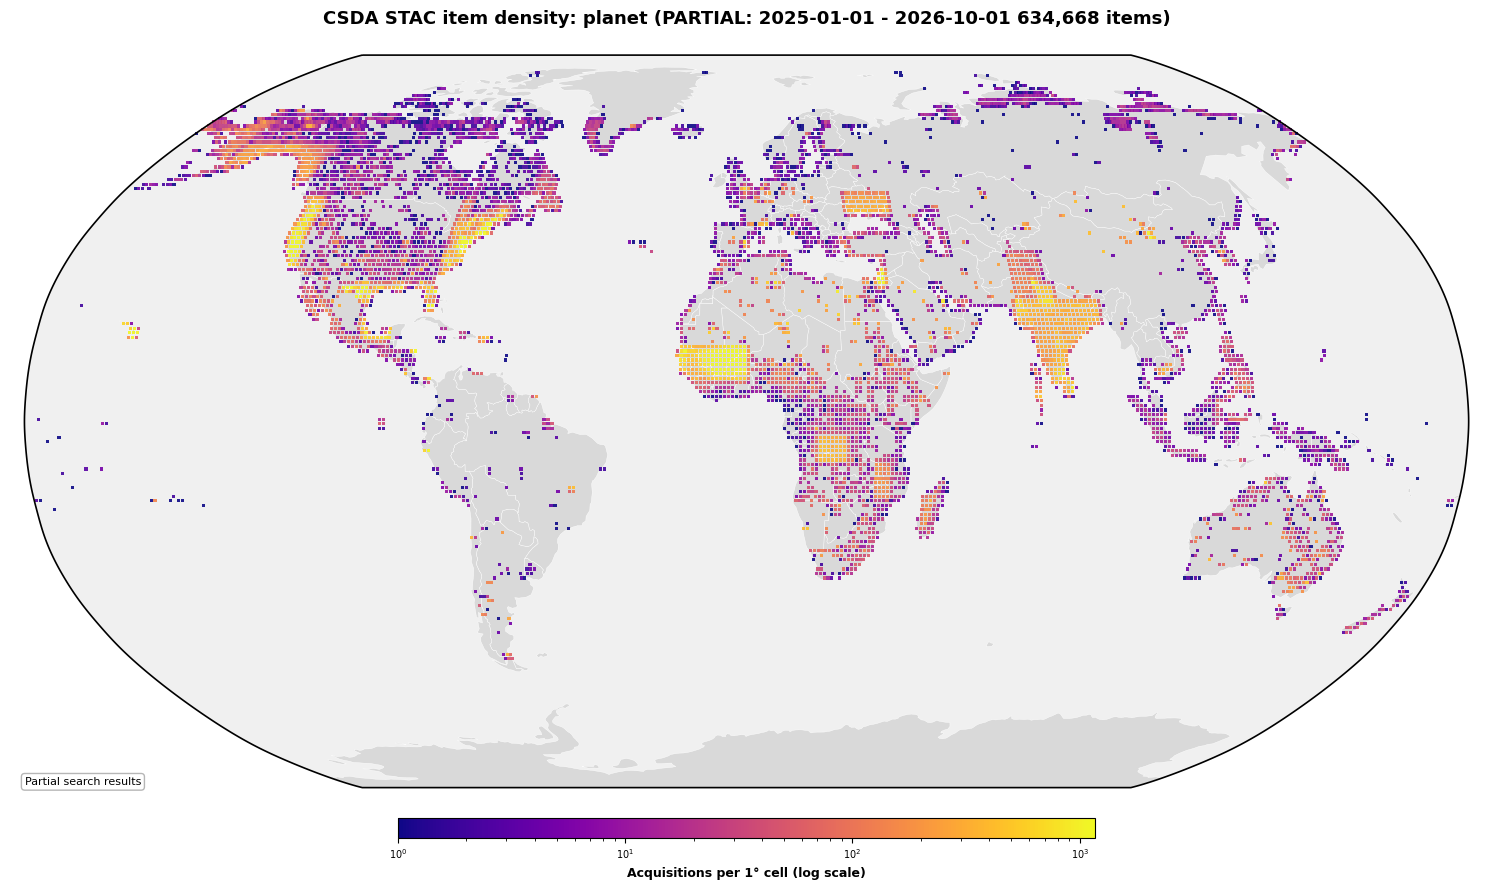

(<Figure size 1800x900 with 2 Axes>,
 <Axes: title={'center': 'CSDA STAC item density: planet (PARTIAL: 2025-01-01 - 2026-10-01 634,668 items)'}>)

In [22]:
# RUN_DIR = Path('/explore/nobackup/people/pmontesa/csda_stac_cache/global_search/e3655091bc88bc19')
# KEEP = ['datetime', 'platform', 'instrument']

# stac_gdf = load_light(RUN_DIR)

MINDATE = "2025-01-01"

if stac_gdf.empty:
    print('Nothing to map yet — check back once post-2014 slices complete.')
else:
    
    stac_gdf_subset = stac_gdf[stac_gdf["datetime"] > MINDATE]
    fig = staclib.plot_stac_acquisition_density(
        stac_gdf=stac_gdf_subset, sites_gdf=None, bin_method='grid',
        title=f'CSDA STAC item density: planet (PARTIAL: {MINDATE} - {date.today().isoformat()} {len(stac_gdf_subset):,} items)',
        filter_text='Partial search results',
        figsize=(18, 9))
    display(fig)